<a href="https://colab.research.google.com/github/BHAGI-99/CS5998-Capstone-Project-P.B.W.Nanayakkara-268472T/blob/main/notebooks/01_eda_baselines_cnn.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [2]:
!git clone https://github.com/BHAGI-99/CS5998-Capstone-Project-P.B.W.Nanayakkara-268472T.git project
%cd project
!python src/download_data.py
!python src/segment.py

Cloning into 'project'...
remote: Enumerating objects: 17, done.
remote: Counting objects: 100% (17/17), done.
remote: Compressing objects: 100% (15/15), done.
remote: Total 17 (delta 2), reused 0 (delta 0), pack-reused 0 (from 0)
Receiving objects: 100% (17/17), 91.00 KiB | 30.33 MiB/s, done.
Resolving deltas: 100% (2/2), done.
/content/project
Cloning into 'data/raw/Smart-Sleeve-Dataset'...
remote: Enumerating objects: 445, done.
remote: Counting objects: 100% (445/445), done.
remote: Compressing objects: 100% (318/318), done.
remote: Total 445 (delta 127), reused 443 (delta 127), pack-reused 0 (from 0)
Receiving objects: 100% (445/445), 87.33 MiB | 16.56 MiB/s, done.
Resolving deltas: 100% (127/127), done.
Updating files: 100% (287/287), done.
Done. Data folder: data/raw/Smart-Sleeve-Dataset/Smart-Sleeve Dataset
X (2520, 208, 200) uint16 | classes: 18 | subjects: 14
truncated segments: 123


In [3]:
import tensorflow as tf
print(tf.__version__)

2.21.0


X (2520, 208, 200) | pressure min/max: 0 4014


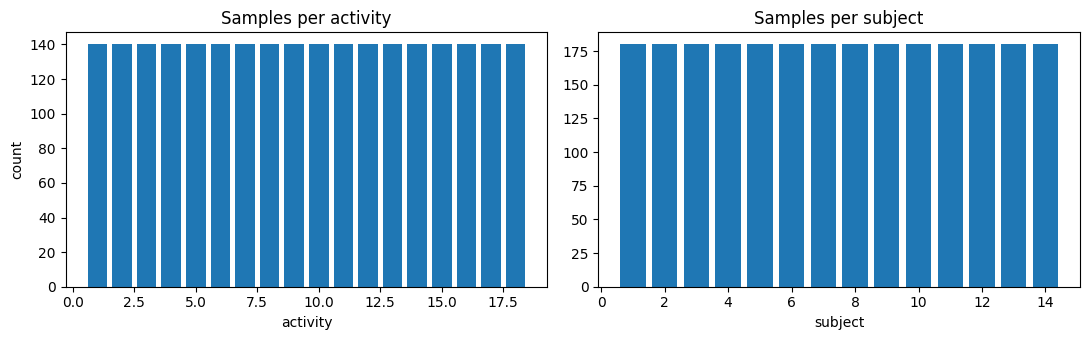

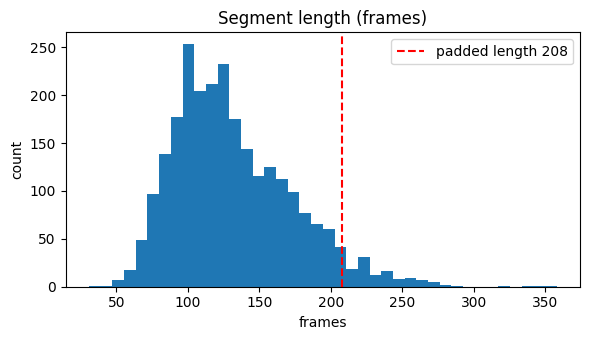

median length 124.0 | truncated: 123


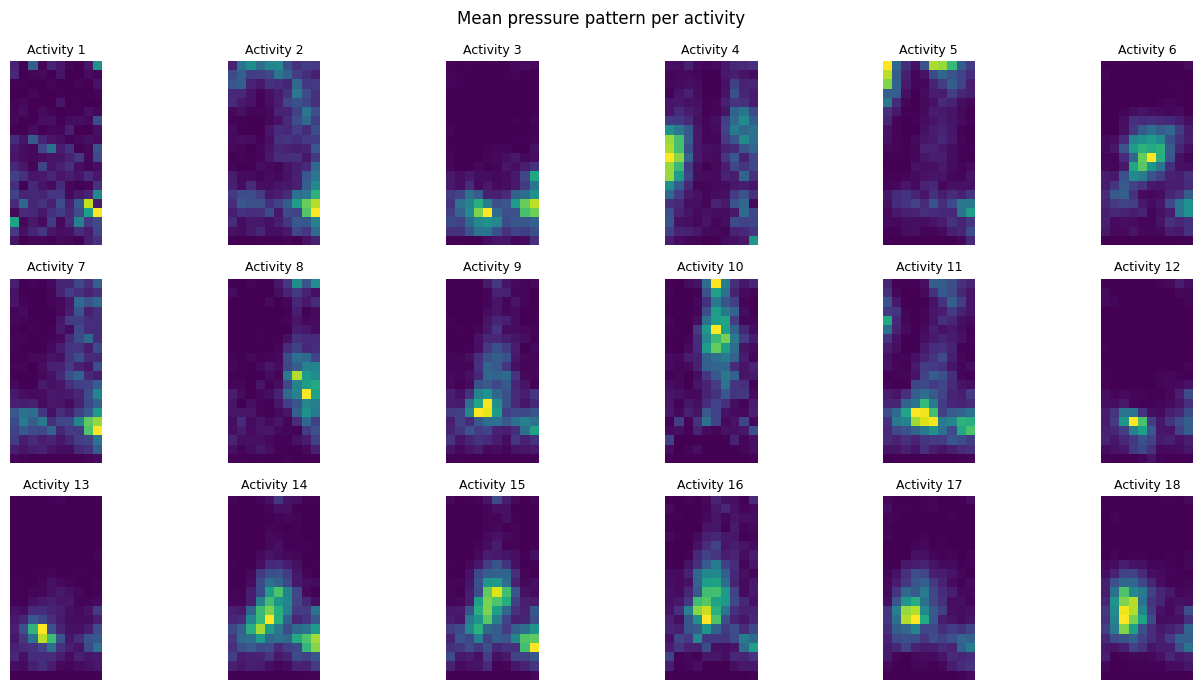

avg change over time: 3.6 | avg pressure: 27.1 | ratio: 0.13


In [4]:
import numpy as np, matplotlib.pyplot as plt
from pathlib import Path
P = Path("data/processed"); F = Path("results/figures"); F.mkdir(parents=True, exist_ok=True)
X = np.load(P/"X.npy"); y = np.load(P/"y.npy"); subj = np.load(P/"subject.npy"); lens = np.load(P/"lengths.npy")
print("X", X.shape, "| pressure min/max:", X.min(), X.max())

# 1. balance of activities and subjects
fig, ax = plt.subplots(1, 2, figsize=(11, 3.5))
ax[0].bar(np.arange(1,19), np.bincount(y)); ax[0].set(title="Samples per activity", xlabel="activity", ylabel="count")
ax[1].bar(np.arange(1,15), np.bincount(subj)[1:]); ax[1].set(title="Samples per subject", xlabel="subject")
plt.tight_layout(); plt.savefig(F/"eda_balance.png", dpi=120); plt.show()

# 2. segment lengths
fig, ax = plt.subplots(figsize=(6,3.5))
ax.hist(lens, bins=40); ax.axvline(208, color="r", ls="--", label="padded length 208")
ax.set(title="Segment length (frames)", xlabel="frames", ylabel="count"); ax.legend()
plt.tight_layout(); plt.savefig(F/"eda_lengths.png", dpi=120); plt.show()
print("median length", np.median(lens), "| truncated:", (lens>208).sum())

# 3. average pressure pattern for each activity (20 x 10 sensor grid)
fig, axes = plt.subplots(3, 6, figsize=(14, 7))
for c, ax in enumerate(axes.ravel()):
    m = np.array([X[i,:min(lens[i],208)].mean(axis=0) for i in np.where(y==c)[0]]).mean(axis=0).reshape(20,10)
    ax.imshow(m, cmap="viridis"); ax.set_title(f"Activity {c+1}", fontsize=9); ax.axis("off")
plt.suptitle("Mean pressure pattern per activity")
plt.tight_layout(); plt.savefig(F/"eda_activity_heatmaps.png", dpi=120); plt.show()

# 4. how much does pressure change over time inside a segment?
sd = np.array([X[i,:min(lens[i],208)].astype(float).std(axis=0).mean() for i in range(len(X))])
mp = np.array([X[i,:min(lens[i],208)].astype(float).mean() for i in range(len(X))])
print("avg change over time: %.1f | avg pressure: %.1f | ratio: %.2f" % (sd.mean(), mp.mean(), sd.mean()/mp.mean()))

In [5]:
import numpy as np, pandas as pd, time
from pathlib import Path
from sklearn.model_selection import StratifiedKFold, LeaveOneGroupOut, cross_val_predict
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, f1_score

SEED = 42; P = Path("data/processed")
X = np.load(P/"X.npy"); y = np.load(P/"y.npy"); subj = np.load(P/"subject.npy"); lens = np.load(P/"lengths.npy")

# Summary features from the real (unpadded) frames: mean, std and max of each of the 200 sensors
feats = []
for i in range(len(X)):
    seg = X[i, :min(lens[i], X.shape[1])].astype(np.float32) / 4095.0   # sensor range is 0-4095
    feats.append(np.concatenate([seg.mean(0), seg.std(0), seg.max(0)]))
F = np.array(feats); print("feature table:", F.shape)

models = {
  "Logistic Regression": make_pipeline(StandardScaler(), LogisticRegression(max_iter=2000)),
  "Random Forest": RandomForestClassifier(n_estimators=200, random_state=SEED, n_jobs=-1),
}
cv10 = StratifiedKFold(10, shuffle=True, random_state=SEED)
rows = []
for name, m in models.items():
    for proto, cv, groups in [("10-fold", cv10, None), ("LOSO", LeaveOneGroupOut(), subj)]:
        t = time.time()
        p = cross_val_predict(m, F, y, cv=cv, groups=groups)
        acc, f1 = accuracy_score(y, p), f1_score(y, p, average="macro")
        rows.append([name, proto, round(acc, 4), round(f1, 4)])
        print(f"{name:20s} {proto:8s} acc={acc:.4f}  macroF1={f1:.4f}  ({time.time()-t:.0f}s)")
Path("results").mkdir(exist_ok=True)
pd.DataFrame(rows, columns=["model", "protocol", "accuracy", "macro_f1"]).to_csv("results/baselines.csv", index=False)

feature table: (2520, 600)
Logistic Regression  10-fold  acc=0.6861  macroF1=0.6867  (37s)
Logistic Regression  LOSO     acc=0.5933  macroF1=0.5931  (56s)
Random Forest        10-fold  acc=0.7433  macroF1=0.7398  (38s)
Random Forest        LOSO     acc=0.6651  macroF1=0.6600  (54s)


In [6]:
import os; os.environ["TF_CPP_MIN_LOG_LEVEL"] = "3"
import numpy as np, pandas as pd, tensorflow as tf, time
from pathlib import Path
from sklearn.model_selection import StratifiedKFold, train_test_split
from sklearn.metrics import accuracy_score, f1_score
from tensorflow.keras import layers

SEED = 42
def set_seed(s=SEED):
    np.random.seed(s); tf.random.set_seed(s); tf.keras.utils.set_random_seed(s)
set_seed()
P = Path("data/processed")
X = np.load(P/"X.npy").astype(np.float32) / 4095.0      # sensor range is 0-4095
y = np.load(P/"y.npy")

def build_cnn(seq_len=208, n_feat=200, n_classes=18):
    inp = tf.keras.Input(shape=(seq_len, n_feat))
    x = layers.Conv1D(64, 5, padding="same")(inp);  x = layers.BatchNormalization()(x); x = layers.ReLU()(x)
    x = layers.Conv1D(128, 5, padding="same")(x);   x = layers.BatchNormalization()(x); x = layers.ReLU()(x)
    x = layers.Conv1D(128, 3, padding="same", name="last_conv")(x); x = layers.BatchNormalization()(x); x = layers.ReLU()(x)
    x = layers.GlobalAveragePooling1D()(x)               # needed later for CAM
    x = layers.Dropout(0.3)(x)
    out = layers.Dense(n_classes, activation="softmax")(x)
    m = tf.keras.Model(inp, out)
    m.compile(optimizer=tf.keras.optimizers.Adam(1e-3), loss="sparse_categorical_crossentropy", metrics=["accuracy"])
    return m

def train_predict(tr, te, max_epochs=60):
    set_seed()
    tr_in, va = train_test_split(tr, test_size=0.1, stratify=y[tr], random_state=SEED)   # validation comes from the training part only
    m = build_cnn()
    es = tf.keras.callbacks.EarlyStopping(monitor="val_loss", patience=8, restore_best_weights=True)
    h = m.fit(X[tr_in], y[tr_in], validation_data=(X[va], y[va]), epochs=max_epochs, batch_size=32, callbacks=[es], verbose=0)
    return m.predict(X[te], verbose=0).argmax(1), len(h.history["loss"])

cv = StratifiedKFold(10, shuffle=True, random_state=SEED)
preds = np.zeros(len(y), dtype=int); rows = []
for k, (tr, te) in enumerate(cv.split(X, y), 1):
    t = time.time()
    p, ep = train_predict(tr, te); preds[te] = p
    acc = accuracy_score(y[te], p); rows.append([k, acc, ep])
    print(f"fold {k:2d}: acc={acc:.4f}  epochs={ep}  ({time.time()-t:.0f}s)")

print(f"\nCNN 10-fold: acc={accuracy_score(y, preds):.4f}  macroF1={f1_score(y, preds, average='macro'):.4f}")
Path("results").mkdir(exist_ok=True)
pd.DataFrame(rows, columns=["fold", "accuracy", "epochs"]).to_csv("results/cnn_10fold_folds.csv", index=False)
np.save("results/cnn_10fold_preds.npy", preds)

fold  1: acc=0.7262  epochs=19  (40s)
fold  2: acc=0.7063  epochs=18  (20s)


fold  3: acc=0.7738  epochs=21  (21s)


fold  4: acc=0.7460  epochs=31  (26s)
fold  5: acc=0.7500  epochs=21  (21s)
fold  6: acc=0.7659  epochs=19  (20s)
fold  7: acc=0.7619  epochs=21  (22s)
fold  8: acc=0.7341  epochs=19  (20s)
fold  9: acc=0.7738  epochs=20  (22s)
fold 10: acc=0.6984  epochs=19  (21s)

CNN 10-fold: acc=0.7437  macroF1=0.7432
